# Cloud Cost Optimization, Part 2: Modeling

In this notebook I compare several models for forecasting the daily cloud cost one month ahead. The data cleaning and EDA are in [Part 1](1_cloud_cost_eda.ipynb).

All the models are from the course. ARIMA, SARIMA and STL with ARIMA are the time series models from Module 10. Ridge regression (Modules 9 and 11), Random Forest and Gradient Boosting (Module 20) are regression models that use date and lag features. In section 12 I also try two libraries from outside the course, XGBoost and Prophet.

Sections:
1. Load the daily cost
2. Train/test split and metric
3. Baselines
4. ARIMA
5. SARIMA
6. STL decomposition + ARIMA
7. Regression models with GridSearchCV
8. December results
9. A closer look at the tuning
10. Cross-validation: backtest over several months
11. Feature engineering and feature selection
12. Two libraries from outside the course: XGBoost and Prophet
13. Residual check
14. Modeling summary
15. Using the forecast as a spend alert
16. Findings and recommendations
17. Next steps

In [1]:
import itertools
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint, uniform
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from xgboost import XGBRegressor
from prophet import Prophet

warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').disabled = True    # Prophet prints a lot of progress messages otherwise
sns.set_theme(style='whitegrid')

## 1. Load the daily cost

Same data as Part 1. The cleaning didn't remove any rows, so I can go straight to the daily total.

In [2]:
df = pd.read_csv('data/cloud_budget_2023_dataset.csv', parse_dates=['date'])

# total amortized cost per day
daily = df.groupby('date')['amortized_cost'].sum().asfreq('D')
print(len(daily), 'days from', daily.index.min().date(), 'to', daily.index.max().date())

365 days from 2023-01-01 to 2023-12-31


## 2. Train/test split and metric

I train on January to November and test on December. It's time series data, so the split has to be by date, not random.

The main metric is MAPE (mean absolute percentage error). It's easy to explain ("the forecast is off by about 5% per day"), and it doesn't depend on the size of the budget. MAPE can break when actual values are close to 0, but daily cost is never below about $600 here. I also show MAE and RMSE in dollars. My goal from the Module 16 proposal was a MAPE under 10%.

In [3]:
train = daily[:'2023-11-30']
test = daily['2023-12-01':]
print('train:', len(train), 'days | test:', len(test), 'days')


def get_scores(actual, pred):
    return {
        'MAPE %': round(mean_absolute_percentage_error(actual, pred) * 100, 2),
        'MAE': round(mean_absolute_error(actual, pred), 2),
        'RMSE': round(root_mean_squared_error(actual, pred), 2)
    }

train: 334 days | test: 31 days


## 3. Baselines

Any real model has to beat these simple rules:
- Naive: every day = the last known day.
- Seasonal naive: repeat the last known week.

In [4]:
def naive_forecast(history, days):
    return np.repeat(history.iloc[-1], days)


def seasonal_naive_forecast(history, days):
    last_week = history.iloc[-7:].values
    return np.tile(last_week, days // 7 + 1)[:days]


preds = {}    # December forecasts from every model
preds['naive'] = pd.Series(naive_forecast(train, len(test)), index=test.index)
preds['seasonal naive'] = pd.Series(seasonal_naive_forecast(train, len(test)), index=test.index)

pd.DataFrame({name: get_scores(test, p) for name, p in preds.items()}).T

,MAPE %,MAE,RMSE
naive,13.88,140.64,188.04
seasonal naive,7.29,86.97,112.44


## 4. ARIMA

I start with a plain ARIMA, which has no seasonal part. The ADF test in Part 1 showed the series isn't stationary, so I use one difference (d = 1). I grid search p and q and pick the lowest AIC. AIC rewards a good fit but penalizes extra parameters, and it only uses the training data.

In [5]:
def search_arima(history):
    results = []
    for p, q in itertools.product([0, 1, 2], [0, 1, 2]):
        model = ARIMA(history, order=(p, 1, q)).fit()
        results.append({'order': (p, 1, q), 'AIC': round(model.aic, 1)})
    return pd.DataFrame(results).sort_values('AIC').reset_index(drop=True)


arima_results = search_arima(train)
arima_order = arima_results.loc[0, 'order']

arima = ARIMA(train, order=arima_order).fit()
preds['ARIMA'] = arima.forecast(len(test))

print('ARIMA', arima_order)
get_scores(test, preds['ARIMA'])

ARIMA (2, 1, 2)


{'MAPE %': 12.54, 'MAE': 137.38, 'RMSE': 160.21}

ARIMA is worse than the seasonal naive baseline. Without a seasonal part it can't repeat the weekend dip, so the forecast quickly flattens into a line.

## 5. SARIMA

SARIMA adds a seasonal part on top of ARIMA. In Part 1 the weekly difference made the series stationary, so I set the season to 7 days with D = 1, keep d = 1, and grid search the rest by AIC.

In [6]:
def search_sarima(history):
    results = []
    for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
        model = SARIMAX(history, order=(p, 1, q), seasonal_order=(P, 1, Q, 7),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        results.append({'order': (p, 1, q), 'seasonal_order': (P, 1, Q, 7), 'AIC': round(model.aic, 1)})
    return pd.DataFrame(results).sort_values('AIC').reset_index(drop=True)


sarima_results = search_sarima(train)
print('models tried:', len(sarima_results))
sarima_results.head()

models tried: 36


,order,seasonal_order,AIC
0,"(0, 1, 2)","(0, 1, 1, 7)",3594.7
1,"(1, 1, 2)","(0, 1, 1, 7)",3595.8
2,"(0, 1, 2)","(1, 1, 1, 7)",3596.4
3,"(1, 1, 2)","(1, 1, 1, 7)",3597.5
4,"(2, 1, 2)","(0, 1, 1, 7)",3597.6


In [7]:
best_order = sarima_results.loc[0, 'order']
best_seasonal = sarima_results.loc[0, 'seasonal_order']

sarima = SARIMAX(train, order=best_order, seasonal_order=best_seasonal,
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarima_forecast = sarima.get_forecast(steps=len(test))
preds['SARIMA'] = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()    # 95% interval, used for the chart later

print('SARIMA', best_order, best_seasonal)
get_scores(test, preds['SARIMA'])

SARIMA (0, 1, 2) (0, 1, 1, 7)


{'MAPE %': 6.4, 'MAE': 70.69, 'RMSE': 83.6}

## 6. STL decomposition + ARIMA

This is the `STLForecast` approach from Module 10. STL splits the series into trend, weekly season and remainder. ARIMA then forecasts the series with the weekly season removed, and the last week of the season is added back on top. I grid search the ARIMA order, with and without a trend term, and again pick by AIC.

In [8]:
def search_stl(history):
    results = []
    for p, q in itertools.product([0, 1, 2], [0, 1, 2]):
        for trend in ['n', 't']:
            model = STLForecast(history, ARIMA, model_kwargs={'order': (p, 1, q), 'trend': trend}, period=7).fit()
            results.append({'order': (p, 1, q), 'trend': trend, 'AIC': round(model.model_result.aic, 1)})
    return pd.DataFrame(results).sort_values('AIC').reset_index(drop=True)


stl_results = search_stl(train)
stl_results.head()

,order,trend,AIC
0,"(2, 1, 2)",n,3644.5
1,"(2, 1, 1)",n,3644.6
2,"(0, 1, 1)",n,3644.8
3,"(2, 1, 2)",t,3645.9
4,"(2, 1, 1)",t,3646.0


In [9]:
stl_order = stl_results.loc[0, 'order']
stl_trend = stl_results.loc[0, 'trend']

stl_arima = STLForecast(train, ARIMA, model_kwargs={'order': stl_order, 'trend': stl_trend}, period=7).fit()
preds['STL + ARIMA'] = stl_arima.forecast(len(test))

print('STL + ARIMA', stl_order, 'trend =', stl_trend)
get_scores(test, preds['STL + ARIMA'])

STL + ARIMA (2, 1, 2) trend = n


{'MAPE %': 5.56, 'MAE': 65.71, 'RMSE': 84.92}

## 7. Regression models with GridSearchCV

Next I try three regression models that learn from features instead of from the series itself: Ridge regression, Random Forest and Gradient Boosting.

The features need some care. I forecast a whole month at once, so on December 31 I don't know the cost from December 30 yet. That means I can only use lags that are at least 31 days old. I use 35 and 42 days, which land on the same weekday as the target day.

The calendar features are `day_of_week`, `is_weekend`, `month` and `day`, which are always known ahead of time. The lag features are `lag_35` and `lag_42` (the cost 5 and 6 weeks earlier, on the same weekday) and `rolling_35` (the 7 day average cost ending 35 days earlier).

In [10]:
def make_features(series):
    features = pd.DataFrame(index=series.index)
    features['day_of_week'] = features.index.dayofweek
    features['is_weekend'] = (features['day_of_week'] >= 5).astype(int)
    features['month'] = features.index.month
    features['day'] = features.index.day
    features['lag_35'] = series.shift(35)
    features['lag_42'] = series.shift(42)
    features['rolling_35'] = series.shift(35).rolling(7).mean()
    return features


features = make_features(daily).dropna()    # the first 42 days have no lag values
X_train = features[:'2023-11-30']
y_train = daily[X_train.index]
X_test = features['2023-12-01':]

# Ridge is a linear model, so day of week needs to be one-hot encoded
features_linear = pd.get_dummies(features, columns=['day_of_week'], drop_first=True, dtype=int)
X_train_linear = features_linear[:'2023-11-30']
X_test_linear = features_linear['2023-12-01':]
print(X_train.shape, X_train_linear.shape)

(292, 7) (292, 12)


For the grid search I use `TimeSeriesSplit` as the `cv` in `GridSearchCV` instead of the default k-fold. Normal k-fold would let the model train on later days and validate on earlier ones. `TimeSeriesSplit` always trains on the past and validates on the days right after, which is how the forecast is used in practice.

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

ridge_pipe = Pipeline([('scale', StandardScaler()), ('ridge', Ridge())])
ridge_grid = GridSearchCV(ridge_pipe, param_grid={'ridge__alpha': [0.1, 1, 10, 100, 1000]},
                          cv=tscv, scoring='neg_mean_absolute_percentage_error')
ridge_grid.fit(X_train_linear, y_train)

rf_grid = GridSearchCV(RandomForestRegressor(random_state=42),
                       param_grid={'n_estimators': [100, 300], 'max_depth': [2, 3, 5, None], 'min_samples_leaf': [1, 5, 10]},
                       cv=tscv, scoring='neg_mean_absolute_percentage_error')
rf_grid.fit(X_train, y_train)

gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=42),
                       param_grid={'n_estimators': [50, 100, 300], 'max_depth': [1, 2, 3], 'learning_rate': [0.01, 0.05, 0.1]},
                       cv=tscv, scoring='neg_mean_absolute_percentage_error')
gb_grid.fit(X_train, y_train)

# sklearn returns negative MAPE (higher is better), so I flip the sign
for name, grid in [('Ridge', ridge_grid), ('Random Forest', rf_grid), ('Gradient Boosting', gb_grid)]:
    print(name, 'best params:', grid.best_params_)
    print(name, 'CV MAPE:', round(-grid.best_score_ * 100, 2), '%')

Ridge best params: {'ridge__alpha': 100}
Ridge CV MAPE: 9.38 %
Random Forest best params: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 100}
Random Forest CV MAPE: 9.14 %
Gradient Boosting best params: {'learning_rate': 0.01, 'max_depth': 1, 'n_estimators': 300}
Gradient Boosting CV MAPE: 8.8 %


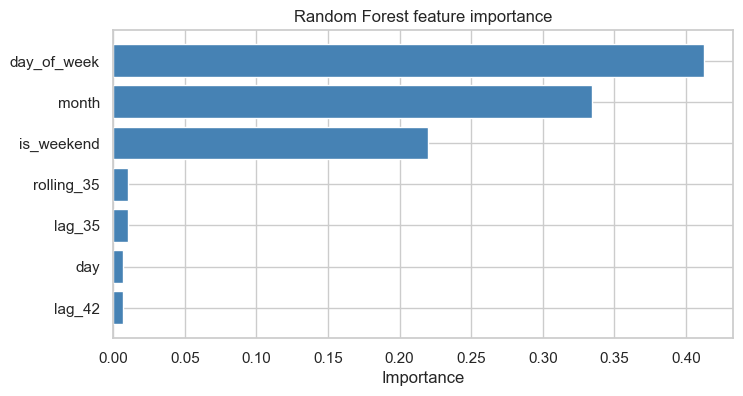

In [12]:
preds['Ridge'] = pd.Series(ridge_grid.predict(X_test_linear), index=test.index)
preds['Random Forest'] = pd.Series(rf_grid.predict(X_test), index=test.index)
preds['Gradient Boosting'] = pd.Series(gb_grid.predict(X_test), index=test.index)

importance = pd.Series(rf_grid.best_estimator_.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 4))
plt.barh(importance.index, importance.values, color='steelblue')
plt.title('Random Forest feature importance')
plt.xlabel('Importance')
plt.show()

Day of week, month and the weekend flag do almost all the work, and the old lags barely matter. One thing to be careful about with `month`: December never appears in the training data, so the trees treat it like the closest month they've seen (November). The tuned trees use fairly large leaves (at least 10 days each), which mix November with the cheaper months before it. So the trees forecast December about 5% too low, and they can't predict a new jump either.

Ridge is different. It fits one straight line, so it learned a slow, steady increase across the year. That line can't reach the new level spend jumped to in November, so Ridge under-forecasts December (about $1,010 a day against an actual $1,163).

## 8. December results

In [13]:
results = pd.DataFrame({name: get_scores(test, p) for name, p in preds.items()}).T.sort_values('MAPE %')
results['Dec total error %'] = [round((preds[name].sum() / test.sum() - 1) * 100, 1) for name in results.index]
results

,MAPE %,MAE,RMSE,Dec total error %
STL + ARIMA,5.56,65.71,84.92,-1.4
SARIMA,6.40,70.69,83.60,1.9
seasonal naive,7.29,86.97,112.44,-1.5
Gradient Boosting,7.30,88.73,112.06,-5.2
Random Forest,8.02,87.62,108.59,-4.9
Ridge,12.46,152.23,175.28,-13.1
ARIMA,12.54,137.38,160.21,-0.4
naive,13.88,140.64,188.04,7.6


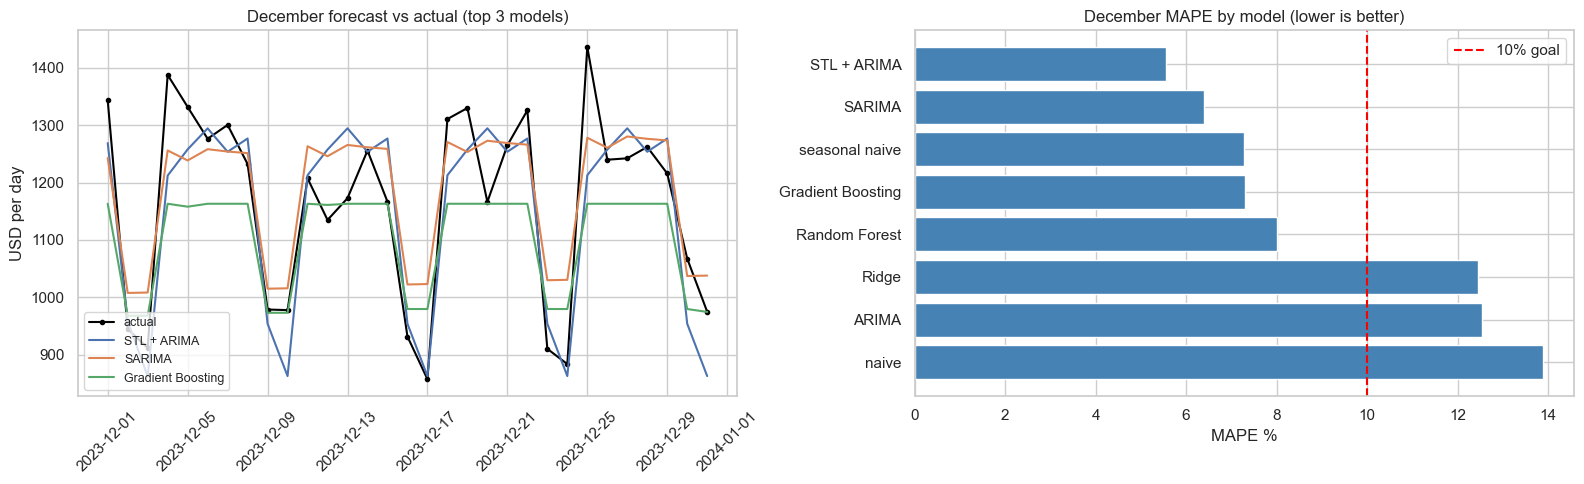

In [14]:
# best 3 models, leaving out the two baselines
top_models = [name for name in results.index if 'naive' not in name][:3]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(test, color='black', marker='o', markersize=3, label='actual')
for name in top_models:
    axes[0].plot(preds[name], label=name)
axes[0].set_title('December forecast vs actual (top 3 models)')
axes[0].set_ylabel('USD per day')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(loc='lower left', fontsize=9)

mape_sorted = results['MAPE %'].sort_values(ascending=False)
axes[1].barh(mape_sorted.index, mape_sorted.values, color='steelblue')
axes[1].axvline(10, color='red', linestyle='--', label='10% goal')
axes[1].set_title('December MAPE by model (lower is better)')
axes[1].set_xlabel('MAPE %')
axes[1].legend()

plt.tight_layout()
plt.savefig('images/december_forecast.png', dpi=100)
plt.show()

## 9. A closer look at the tuning

Sections 4 to 7 only print the best settings from each search. In this section I look at the searches themselves: which settings came close, how much the settings matter, whether tuning actually beat the default settings, and whether a wider random search finds anything better. All the tuning uses only January to November. December is only used to report the result, never to pick the settings.

First, the top 5 settings from each grid search. The `std` column is how much the MAPE varied across the 5 `TimeSeriesSplit` folds.

In [15]:
def top_settings(grid, n=5):
    cv = pd.DataFrame(grid.cv_results_)
    table = pd.DataFrame(list(cv['params'])).astype(object).fillna('None')
    table['CV MAPE %'] = (-cv['mean_test_score'] * 100).round(2)
    table['std %'] = (cv['std_test_score'] * 100).round(2)
    return table.sort_values('CV MAPE %').reset_index(drop=True)


for name, grid in [('Ridge', ridge_grid), ('Random Forest', rf_grid), ('Gradient Boosting', gb_grid)]:
    table = top_settings(grid)
    print(name, '-', len(table), 'combinations tried, CV MAPE from',
          table['CV MAPE %'].min(), '% to', table['CV MAPE %'].max(), '%')
    display(table.head(5))

Ridge - 5 combinations tried, CV MAPE from 9.38 % to 10.95 %


,ridge__alpha,CV MAPE %,std %
0,100.0,9.38,2.98
1,10.0,10.43,2.71
2,1000.0,10.69,2.78
3,1.0,10.88,2.81
4,0.1,10.95,2.82


Random Forest - 24 combinations tried, CV MAPE from 9.14 % to 10.33 %


,max_depth,min_samples_leaf,n_estimators,CV MAPE %,std %
0,5.0,10,100,9.14,3.77
1,None,10,100,9.14,3.77
2,3.0,10,300,9.15,3.75
3,5.0,10,300,9.15,3.74
4,3.0,10,100,9.15,3.78


Gradient Boosting - 27 combinations tried, CV MAPE from 8.8 % to 10.0 %


,learning_rate,max_depth,n_estimators,CV MAPE %,std %
0,0.01,1,300,8.80,3.38
1,0.05,1,50,8.83,3.31
2,0.05,2,50,8.86,3.75
3,0.05,1,100,8.88,3.66
4,0.1,1,50,8.91,3.65


The heatmaps show the CV MAPE for two settings at a time. For Random Forest I hold `n_estimators` at its best value (100), and for Gradient Boosting I hold `max_depth` at its best value (1).

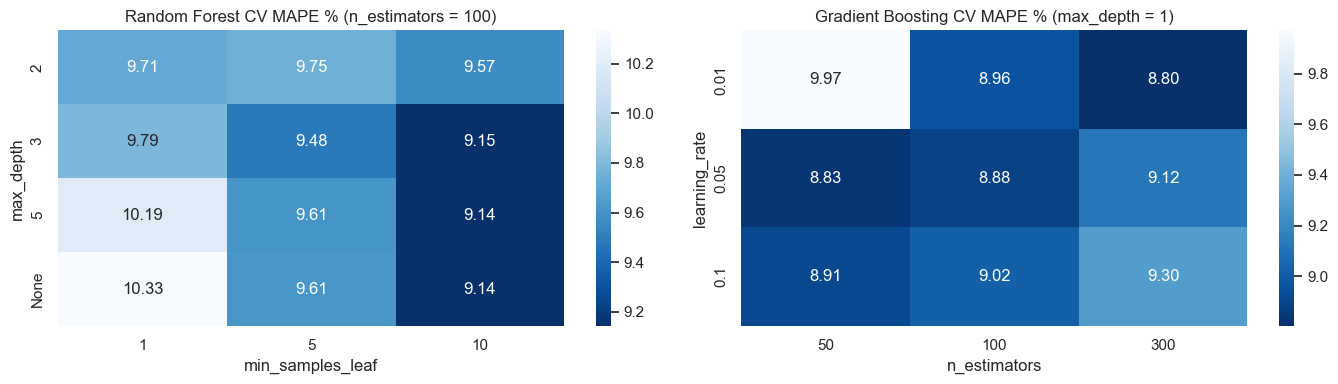

In [16]:
rf_cv = pd.DataFrame(rf_grid.cv_results_)
rf_cv['CV MAPE %'] = -rf_cv['mean_test_score'] * 100
rf_cv['param_max_depth'] = rf_cv['param_max_depth'].fillna('None').astype(str)    # so None shows up as a label
rf_cv = rf_cv[rf_cv['param_n_estimators'] == rf_grid.best_params_['n_estimators']]
rf_table = rf_cv.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='CV MAPE %')

gb_cv = pd.DataFrame(gb_grid.cv_results_)
gb_cv['CV MAPE %'] = -gb_cv['mean_test_score'] * 100
gb_cv = gb_cv[gb_cv['param_max_depth'] == gb_grid.best_params_['max_depth']]
gb_table = gb_cv.pivot(index='param_learning_rate', columns='param_n_estimators', values='CV MAPE %')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(rf_table, annot=True, fmt='.2f', cmap='Blues_r', ax=axes[0])
axes[0].set_title('Random Forest CV MAPE % (n_estimators = 100)')
axes[0].set_xlabel('min_samples_leaf')
axes[0].set_ylabel('max_depth')
sns.heatmap(gb_table, annot=True, fmt='.2f', cmap='Blues_r', ax=axes[1])
axes[1].set_title('Gradient Boosting CV MAPE % (max_depth = 1)')
axes[1].set_xlabel('n_estimators')
axes[1].set_ylabel('learning_rate')
plt.tight_layout()
plt.savefig('images/grid_search.png', dpi=100)
plt.show()

Next, I compare each tuned model with the same model using scikit-learn's default settings. The default CV MAPE uses `cross_val_score` with the same `TimeSeriesSplit`, so both columns are scored the same way.

In [17]:
default_models = [
    ('Ridge', Pipeline([('scale', StandardScaler()), ('ridge', Ridge())]), X_train_linear, X_test_linear, ridge_grid),
    ('Random Forest', RandomForestRegressor(random_state=42), X_train, X_test, rf_grid),
    ('Gradient Boosting', GradientBoostingRegressor(random_state=42), X_train, X_test, gb_grid)
]

tuning_rows = []
for name, model, X_tr, X_te, grid in default_models:
    default_cv = -cross_val_score(model, X_tr, y_train, cv=tscv, scoring='neg_mean_absolute_percentage_error').mean()
    model.fit(X_tr, y_train)
    tuning_rows.append({
        'model': name,
        'default CV MAPE %': round(default_cv * 100, 2),
        'tuned CV MAPE %': round(-grid.best_score_ * 100, 2),
        'default Dec MAPE %': get_scores(test, model.predict(X_te))['MAPE %'],
        'tuned Dec MAPE %': get_scores(test, preds[name])['MAPE %']
    })

pd.DataFrame(tuning_rows).set_index('model')

,default CV MAPE %,tuned CV MAPE %,default Dec MAPE %,tuned Dec MAPE %
model,,,,
Ridge,10.88,9.38,12.71,12.46
Random Forest,10.33,9.14,5.51,8.02
Gradient Boosting,9.72,8.80,6.78,7.30


A grid search only tries the values I list. To check that I didn't miss a better area, I also ran a `RandomizedSearchCV` on Gradient Boosting over wider ranges, including two settings that weren't in the grid (`min_samples_leaf` and `subsample`). It tries 50 random combinations with the same `TimeSeriesSplit`.

In [18]:
gb_random = RandomizedSearchCV(GradientBoostingRegressor(random_state=42),
                               param_distributions={'n_estimators': randint(50, 500),
                                                    'max_depth': randint(1, 5),
                                                    'learning_rate': uniform(0.005, 0.195),
                                                    'min_samples_leaf': randint(1, 30),
                                                    'subsample': uniform(0.6, 0.4)},
                               n_iter=50, cv=tscv, scoring='neg_mean_absolute_percentage_error', random_state=42)
gb_random.fit(X_train, y_train)

print('random search best params:')
for k, v in gb_random.best_params_.items():
    print(' ', k, '=', round(v, 3))
pd.DataFrame({
    'CV MAPE %': [round(-gb_grid.best_score_ * 100, 2), round(-gb_random.best_score_ * 100, 2)],
    'Dec MAPE %': [get_scores(test, preds['Gradient Boosting'])['MAPE %'],
                   get_scores(test, gb_random.predict(X_test))['MAPE %']]
}, index=['grid search (27 combinations)', 'random search (50 combinations)'])

random search best params:
  learning_rate = 0.058
  max_depth = 1
  min_samples_leaf = 24
  n_estimators = 459
  subsample = 0.986


,CV MAPE %,Dec MAPE %
grid search (27 combinations),8.80,7.3
random search (50 combinations),9.02,6.3


The time series models were tuned by AIC instead of cross-validation. AIC only uses the training data, so it's worth checking whether the lowest AIC also gives a good forecast. Here are the top 5 SARIMA orders by AIC, with the December MAPE each one would have had.

In [19]:
sarima_check = sarima_results.head(5).copy()
dec_mape = []
for i, row in sarima_check.iterrows():
    model = SARIMAX(train, order=row['order'], seasonal_order=row['seasonal_order'],
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    dec_mape.append(get_scores(test, model.forecast(len(test)))['MAPE %'])
sarima_check['Dec MAPE %'] = dec_mape
sarima_check

,order,seasonal_order,AIC,Dec MAPE %
0,"(0, 1, 2)","(0, 1, 1, 7)",3594.7,6.40
1,"(1, 1, 2)","(0, 1, 1, 7)",3595.8,6.37
2,"(0, 1, 2)","(1, 1, 1, 7)",3596.4,6.46
3,"(1, 1, 2)","(1, 1, 1, 7)",3597.5,6.44
4,"(2, 1, 2)","(0, 1, 1, 7)",3597.6,6.38


Here is what the tuning shows:

- The settings do matter, but only by about 1 to 1.5 percentage points. Ridge goes from 10.95% to 9.38% depending on `alpha`, Random Forest from 10.33% to 9.14%, and Gradient Boosting from 10.0% to 8.8%.
- For Random Forest, `min_samples_leaf` matters the most. With at least 10 days per leaf and a depth of 3 or more, the CV MAPE is about 9.1%. Small leaves let the trees memorize single days, which doesn't carry over to the next fold. For Gradient Boosting, a small learning rate needs more trees, and a larger learning rate needs fewer, which is the usual trade-off.
- The `std` across folds is about 3 percentage points, much bigger than the gaps between the top settings. So the top few settings of each model are basically tied, and the "best" one is partly luck.
- Tuning beat the default settings on cross-validation for all three models (Ridge 10.88% to 9.38%, Random Forest 10.33% to 9.14%, Gradient Boosting 9.72% to 8.80%).
- In December, though, the default Random Forest (5.5%) and Gradient Boosting (6.8%) did better than the tuned ones. The default trees are more detailed (Random Forest grows full trees with leaves as small as 1 day, and Gradient Boosting uses trees 3 levels deep), so they most likely follow November closely, and December happened to stay at November's level. The tuned models are simpler (Random Forest needs at least 10 days per leaf, and Gradient Boosting uses trees with a single split), so they average November with the cheaper months before it. That was safer across the CV folds, which include level shifts, but it cost them in December. I didn't switch to the defaults, because that would mean picking settings based on the test month. This is the same reason I compare the models on the 9 month backtest in the next section instead of on December alone.
- The random search over wider ranges didn't beat the grid on cross-validation (9.02% vs 8.80%), so the grid already covered the good area. It did a bit better in December (6.3% vs 7.3%), which is the same pattern as above.
- For SARIMA, the top 5 orders by AIC all score between 6.37% and 6.46% in December. So picking the lowest AIC was a safe choice, and the exact order makes almost no difference.

Overall, tuning helped on the validation folds, but with one year of data the gains are small and close to the noise between folds. The bigger improvement came from the weekly season, not from the settings.

## 10. Cross-validation: backtest over several months

One test month could be lucky, so I repeat the whole process for every month from April to December. For each month I train on everything before it, forecast the month, and score it. This is a rolling-origin cross-validation.

Every step is redone inside each month, including the order search and the grid search. That way a month is never used to pick the settings it's scored on. This cell takes a few minutes to run.

In [20]:
backtest = []

for month_start in pd.date_range('2023-04-01', '2023-12-01', freq='MS'):
    month_end = month_start + pd.offsets.MonthEnd(0)
    history = daily[:month_start - pd.Timedelta(days=1)]
    actual = daily[month_start:month_end]
    days = len(actual)

    # time series models: search the orders again on this history
    a_order = search_arima(history).loc[0, 'order']
    s_best = search_sarima(history).loc[0]
    stl_best = search_stl(history).loc[0]

    month_preds = {
        'naive': naive_forecast(history, days),
        'seasonal naive': seasonal_naive_forecast(history, days),
        'ARIMA': ARIMA(history, order=a_order).fit().forecast(days),
        'SARIMA': SARIMAX(history, order=s_best['order'], seasonal_order=s_best['seasonal_order'],
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False).forecast(days),
        'STL + ARIMA': STLForecast(history, ARIMA, model_kwargs={'order': stl_best['order'], 'trend': stl_best['trend']},
                                   period=7).fit().forecast(days)
    }

    # regression models: clone() gives an unfitted copy of each grid search, so the grid search runs again on this history
    last_day = history.index[-1]
    y_hist = daily[features[:last_day].index]
    month_preds['Ridge'] = clone(ridge_grid).fit(features_linear[:last_day], y_hist).predict(features_linear[month_start:month_end])
    month_preds['Random Forest'] = clone(rf_grid).fit(features[:last_day], y_hist).predict(features[month_start:month_end])
    month_preds['Gradient Boosting'] = clone(gb_grid).fit(features[:last_day], y_hist).predict(features[month_start:month_end])

    for name, pred in month_preds.items():
        row = {'month': month_start.strftime('%b'), 'model': name}
        row.update(get_scores(actual, pred))
        backtest.append(row)

backtest = pd.DataFrame(backtest)
month_order = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
mape_table = backtest.pivot(index='model', columns='month', values='MAPE %')[month_order]
mape_table['average'] = mape_table.mean(axis=1).round(2)
mape_table['normal months'] = mape_table[['Apr', 'May', 'Jul', 'Sep', 'Oct', 'Dec']].mean(axis=1).round(2)
mape_table.sort_values('normal months')

month,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,average,normal months
model,,,,,,,,,,,
SARIMA,4.94,5.74,13.18,5.56,16.37,5.84,5.43,22.68,6.40,9.57,5.65
Random Forest,4.21,5.37,12.67,6.74,13.20,6.01,5.50,20.89,8.02,9.18,5.97
STL + ARIMA,8.51,4.87,13.76,5.10,14.58,6.00,6.07,22.51,5.56,9.66,6.02
Gradient Boosting,4.58,5.12,12.37,6.46,10.80,7.98,6.33,20.77,7.30,9.08,6.29
seasonal naive,8.49,6.94,14.79,6.57,13.61,7.01,6.21,22.29,7.29,10.36,7.08
Ridge,6.12,5.49,14.04,8.00,14.30,8.57,6.37,19.66,12.46,10.56,7.84
ARIMA,12.45,9.24,16.72,11.32,15.04,10.15,11.45,22.54,12.54,13.49,11.19
naive,13.40,13.09,10.65,11.91,26.43,14.22,23.30,23.62,13.88,16.72,14.97


The "normal months" column leaves out June, August and November. Those are the months where the spending level shifted: the monthly average went up 16% in June, down 10% in August and up 29% in November (see the monthly bars in Part 1).

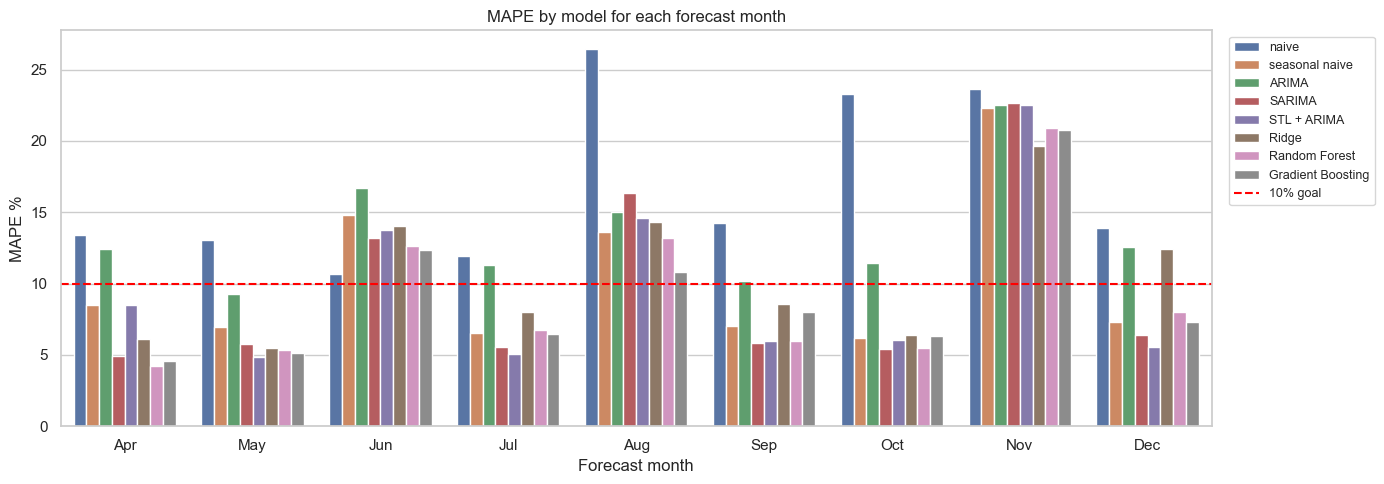

In [21]:
plt.figure(figsize=(14, 5))
sns.barplot(data=backtest, x='month', y='MAPE %', hue='model', order=month_order)
plt.axhline(10, color='red', linestyle='--', label='10% goal')
plt.title('MAPE by model for each forecast month')
plt.xlabel('Forecast month')
plt.ylabel('MAPE %')
plt.legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('images/backtest.png', dpi=100)
plt.show()

## 11. Feature engineering and feature selection

The regression models so far use seven features: four calendar features and three cost lags. In this section I try adding more features, and then use feature selection to see which ones are actually worth keeping.

Every new feature has to be known at least 31 days ahead, for the same reason as in section 7. The new candidates are:
- `week_of_year` and `is_holiday` (the 8 US holidays from Part 1), which are calendar features.
- `rolling_std_35`: how much the cost moved around in the 7 days ending 35 days earlier.
- `change_35_42`: the difference between the 35 and 42 day lags, as a rough trend signal.
- `prod_lag_35`, `staging_lag_35` and `dev_lag_35`: the cost of each environment 35 days earlier, since they behave differently on weekends.
- `usage_lag_35`: total usage 35 days earlier. Usage and cost were strongly related in Part 1 (0.93).

In [22]:
holidays = pd.to_datetime(['2023-01-02', '2023-01-16', '2023-02-20', '2023-05-29',
                           '2023-07-04', '2023-09-04', '2023-11-23', '2023-12-25'])
env_daily = df.pivot_table(index='date', columns='environment', values='amortized_cost', aggfunc='sum').asfreq('D')
usage_daily = df.groupby('date')['usage_quantity'].sum().asfreq('D')


def make_more_features(series):
    features = make_features(series)
    features['week_of_year'] = features.index.isocalendar().week.astype(int)
    features['is_holiday'] = features.index.isin(holidays).astype(int)
    features['rolling_std_35'] = series.shift(35).rolling(7).std()
    features['change_35_42'] = features['lag_35'] - features['lag_42']
    for env in ['prod', 'staging', 'dev']:
        features[env + '_lag_35'] = env_daily[env].shift(35)
    features['usage_lag_35'] = usage_daily.shift(35)
    return features


features_more = make_more_features(daily).dropna()
X_train_more = features_more[:'2023-11-30']
X_test_more = features_more['2023-12-01':]
original_cols = list(X_train.columns)
print('original features:', len(original_cols), '| with the new ones:', features_more.shape[1])
print('same training days as before:', X_train_more.index.equals(X_train.index))

original features: 7 | with the new ones: 15
same training days as before: True


First, the simplest test: run the same grid search with all 15 features and compare it with the original 7.

In [23]:
feature_rows = []
for name, grid in [('Random Forest', rf_grid), ('Gradient Boosting', gb_grid)]:
    more_grid = clone(grid).fit(X_train_more, y_train)
    feature_rows.append({
        'model': name,
        'CV MAPE % (7 features)': round(-grid.best_score_ * 100, 2),
        'CV MAPE % (15 features)': round(-more_grid.best_score_ * 100, 2),
        'Dec MAPE % (7 features)': get_scores(test, preds[name])['MAPE %'],
        'Dec MAPE % (15 features)': get_scores(test, more_grid.predict(X_test_more))['MAPE %']
    })
pd.DataFrame(feature_rows).set_index('model')

,CV MAPE % (7 features),CV MAPE % (15 features),Dec MAPE % (7 features),Dec MAPE % (15 features)
model,,,,
Random Forest,9.14,9.21,8.02,7.66
Gradient Boosting,8.80,8.95,7.30,7.32


Next is permutation importance. It shuffles one feature at a time and measures how much worse the forecast gets, so a feature that doesn't help scores close to 0. It's more reliable than the built-in tree importance in section 7, which tends to favor features with many different values. To keep it fair, I compute it on the validation part of each `TimeSeriesSplit` fold, using the tuned Gradient Boosting settings, and average the 5 folds. December isn't used.

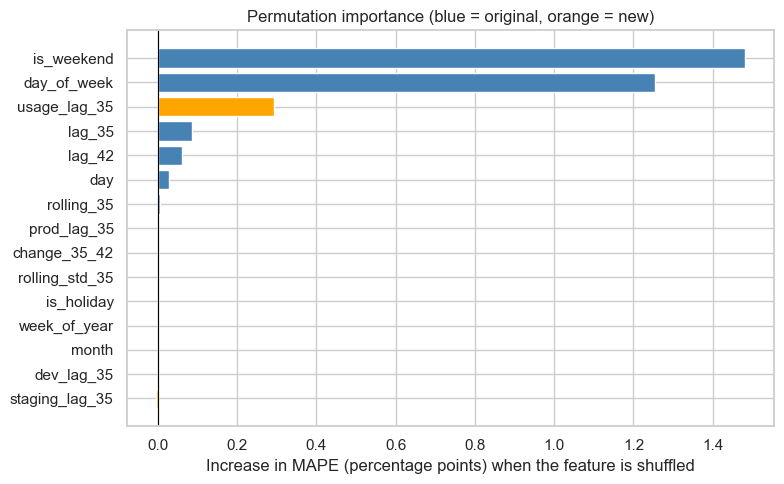

In [24]:
fold_importance = []
for train_idx, val_idx in tscv.split(X_train_more):
    model = clone(gb_grid.best_estimator_).fit(X_train_more.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(model, X_train_more.iloc[val_idx], y_train.iloc[val_idx],
                                    scoring='neg_mean_absolute_percentage_error', n_repeats=10, random_state=42)
    fold_importance.append(result.importances_mean * 100)    # in MAPE percentage points

perm_importance = pd.Series(np.mean(fold_importance, axis=0), index=X_train_more.columns).sort_values()

plt.figure(figsize=(8, 5))
colors = ['steelblue' if col in original_cols else 'orange' for col in perm_importance.index]
plt.barh(perm_importance.index, perm_importance.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Permutation importance (blue = original, orange = new)')
plt.xlabel('Increase in MAPE (percentage points) when the feature is shuffled')
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=100)
plt.show()

Then two ways of selecting features automatically. `SequentialFeatureSelector` (Module 9) starts with no features and adds the one that improves the CV MAPE the most, and keeps going until the next feature improves it by less than 0.1 percentage points. Lasso (Modules 9 and 11) is the linear version: it pushes the coefficients of weak features to exactly 0.

In [25]:
for name, grid in [('Random Forest', rf_grid), ('Gradient Boosting', gb_grid)]:
    sfs = SequentialFeatureSelector(clone(grid.best_estimator_), direction='forward', n_features_to_select='auto',
                                    tol=0.001, cv=tscv, scoring='neg_mean_absolute_percentage_error')
    sfs.fit(X_train_more, y_train)
    selected = list(X_train_more.columns[sfs.get_support()])
    score = -cross_val_score(clone(grid.best_estimator_), X_train_more[selected], y_train, cv=tscv,
                             scoring='neg_mean_absolute_percentage_error').mean()
    print(name, 'keeps:', selected, '| CV MAPE:', round(score * 100, 2), '%')

features_more_linear = pd.get_dummies(features_more, columns=['day_of_week'], drop_first=True, dtype=int)
lasso_grid = GridSearchCV(Pipeline([('scale', StandardScaler()), ('lasso', Lasso(max_iter=50000))]),
                          param_grid={'lasso__alpha': [0.1, 1, 10, 50, 100, 200]},
                          cv=tscv, scoring='neg_mean_absolute_percentage_error')
lasso_grid.fit(features_more_linear[:'2023-11-30'], y_train)
lasso_coef = pd.Series(lasso_grid.best_estimator_.named_steps['lasso'].coef_, index=features_more_linear.columns)
print('\nLasso best alpha:', lasso_grid.best_params_['lasso__alpha'],
      '| CV MAPE:', round(-lasso_grid.best_score_ * 100, 2), '%')
print('Lasso keeps:', list(lasso_coef[lasso_coef != 0].index))
print('Lasso drops', (lasso_coef == 0).sum(), 'of', len(lasso_coef), 'features')

Random Forest keeps: ['day_of_week', 'lag_35'] | CV MAPE: 8.37 %


Gradient Boosting keeps: ['day_of_week'] | CV MAPE: 8.31 %

Lasso best alpha: 50 | CV MAPE: 9.09 %
Lasso keeps: ['is_weekend']
Lasso drops 19 of 20 features


The selection above used all of January to November, so it's not a fair test of the selected features. To check them properly, I repeat the backtest from section 10 for Gradient Boosting, and redo the feature selection inside each month using only the data before it. I compare three versions: the original 7 features (from section 10), all 15 features, and the features `SequentialFeatureSelector` picks for that month. This cell takes a couple of minutes.

In [26]:
selection_rows = []
for month_start in pd.date_range('2023-04-01', '2023-12-01', freq='MS'):
    month_end = month_start + pd.offsets.MonthEnd(0)
    last_day = month_start - pd.Timedelta(days=1)
    X_hist = features_more[:last_day]
    y_hist = daily[X_hist.index]
    X_month = features_more[month_start:month_end]
    actual = daily[month_start:month_end]

    all_grid = clone(gb_grid).fit(X_hist, y_hist)

    # tune on the original features, then let SFS pick from all 15, then tune again on the picked ones
    first_grid = clone(gb_grid).fit(X_hist[original_cols], y_hist)
    sfs = SequentialFeatureSelector(first_grid.best_estimator_, direction='forward', n_features_to_select='auto',
                                    tol=0.001, cv=tscv, scoring='neg_mean_absolute_percentage_error')
    sfs.fit(X_hist, y_hist)
    selected = list(X_hist.columns[sfs.get_support()])
    selected_grid = clone(gb_grid).fit(X_hist[selected], y_hist)

    month = month_start.strftime('%b')
    original_mape = backtest[(backtest['month'] == month) & (backtest['model'] == 'Gradient Boosting')]['MAPE %'].iloc[0]
    selection_rows.append({
        'month': month,
        '7 original features': original_mape,
        'all 15 features': get_scores(actual, all_grid.predict(X_month))['MAPE %'],
        'SFS selected features': get_scores(actual, selected_grid.predict(X_month[selected]))['MAPE %'],
        'features SFS picked': ', '.join(selected)
    })

selection_table = pd.DataFrame(selection_rows).set_index('month')
selection_table

,7 original features,all 15 features,SFS selected features,features SFS picked
month,,,,
Apr,4.58,4.72,4.55,is_weekend
May,5.12,5.14,5.02,is_weekend
Jun,12.37,12.77,12.54,is_weekend
Jul,6.46,6.31,5.05,"is_weekend, month"
Aug,10.80,12.23,10.93,"day_of_week, week_of_year, usage_lag_35"
Sep,7.98,8.20,6.05,day_of_week
Oct,6.33,7.29,5.64,"day_of_week, month"
Nov,20.77,21.25,21.31,"is_weekend, month"
Dec,7.30,7.32,17.05,day_of_week


In [27]:
mape_cols = ['7 original features', 'all 15 features', 'SFS selected features']
pd.DataFrame({
    'normal months': selection_table.loc[['Apr', 'May', 'Jul', 'Sep', 'Oct', 'Dec'], mape_cols].mean(),
    'shift months': selection_table.loc[['Jun', 'Aug', 'Nov'], mape_cols].mean(),
    'all 9 months': selection_table[mape_cols].mean()
}).round(2)

,normal months,shift months,all 9 months
7 original features,6.29,14.65,9.08
all 15 features,6.50,15.42,9.47
SFS selected features,7.23,14.93,9.79


In [28]:
# the loop ends on December, so these are the December values
december_forecast = selected_grid.predict(X_month[selected])
print('December, SFS picked:', selected)
print('average forecast:', round(december_forecast.mean()), 'per day | actual:', round(actual.mean()), 'per day')
print('error on the December total:', round((december_forecast.sum() / actual.sum() - 1) * 100, 1), '%')

December, SFS picked: ['day_of_week']
average forecast: 958 per day | actual: 1163 per day
error on the December total: -17.6 %


Here is what the feature engineering and selection show:

- Adding the 8 new features didn't help. The CV MAPE got slightly worse for both models (Random Forest 9.14% to 9.21%, Gradient Boosting 8.80% to 8.95%), and in the backtest all 15 features did a bit worse than the original 7 in 8 of the 9 months.
- The permutation importance shows why. The weekend flag and day of week matter by far the most, and `usage_lag_35` is the only new feature that helps at all (about 0.3 percentage points). The environment lags, the holiday flag, the trend signal and `week_of_year` score close to 0. The holiday result matches Part 1, where holidays didn't cost less than normal days. `month` also scores about 0 here, but that's because each validation fold comes later in the year than its training data, so the model mostly hasn't seen those month values before.
- Both selection methods end up with very few features. On January to November, `SequentialFeatureSelector` keeps day of week and `lag_35` for Random Forest and only day of week for Gradient Boosting. Lasso keeps only `is_weekend` and drops the other 19. So most of what these models can learn from one year of data is the weekly pattern.
- The fair backtest is more mixed. The selected features did a bit better than the original 7 in five of the six normal months, but in December the error jumped from 7.3% to 17%. In most months SFS picked only calendar features, and with nothing that tells the model the current level of spend, it forecasts close to the average of the past months. That's fine while spend is steady, but December stayed at November's higher level, and the forecast came out about 18% too low ($958 a day against an actual $1,163). The picked features also changed almost every month, so the selection isn't stable.

So I'm keeping the original 7 features. The extra features don't add anything, and the smaller sets are risky because they drop the lag features that tell the model where spend is right now. This is the same conclusion as the tuning section: with one year of data, the weekly pattern is most of what there is to learn, and it's also why SARIMA is still the final model.

## 12. Two libraries from outside the course: XGBoost and Prophet

All the models so far are from the course. Here I try two popular libraries that weren't covered, and test them exactly the same way: the December test and the 9 month backtest, with all tuning done only on the data before each forecast month.

[XGBoost](https://xgboost.readthedocs.io/) is a gradient boosting library that's widely used in practice. It works like the Gradient Boosting model from section 7, but adds regularization and row sampling. Because it follows the scikit-learn API, it plugs straight into `GridSearchCV` with `TimeSeriesSplit` and uses the same 7 features.

[Prophet](https://facebook.github.io/prophet/) is Meta's forecasting library, built for daily business data. It fits a trend made of straight line pieces, a weekly season and holiday effects, and it can bend the trend at points where the data changes direction. That sounds like a good match for this data, especially for the level shifts, so it's worth testing.

XGBoost first. The grid is similar to the Gradient Boosting one, plus `subsample` (the share of days each tree is trained on).

In [29]:
xgb_grid = GridSearchCV(XGBRegressor(random_state=42, n_jobs=1),
                        param_grid={'n_estimators': [100, 300], 'max_depth': [1, 2, 3],
                                    'learning_rate': [0.01, 0.05, 0.1], 'subsample': [0.8, 1.0]},
                        cv=tscv, scoring='neg_mean_absolute_percentage_error')
xgb_grid.fit(X_train, y_train)

extra_preds = {}    # December forecasts from the two new libraries
extra_preds['XGBoost'] = pd.Series(xgb_grid.predict(X_test), index=test.index)
print('XGBoost best params:', xgb_grid.best_params_)
print('XGBoost CV MAPE:', round(-xgb_grid.best_score_ * 100, 2), '%')
get_scores(test, extra_preds['XGBoost'])

XGBoost best params: {'learning_rate': 0.01, 'max_depth': 1, 'n_estimators': 300, 'subsample': 1.0}
XGBoost CV MAPE: 8.81 %


{'MAPE %': 7.4, 'MAE': 90.13, 'RMSE': 113.41}

Prophet's most important setting is `changepoint_prior_scale`, which controls how easily the trend can bend. A small value gives an almost straight trend, and a large value lets it follow every change. Prophet doesn't work with `GridSearchCV`, so I tune it with a simple holdout: fit on the history minus its last 30 days, forecast those 30 days, and keep the value with the lowest MAPE. I use the same 8 holidays as Part 1 and turn off the yearly season, since there's only one year of data.

In [30]:
prophet_holidays = pd.DataFrame({'holiday': 'us_holiday', 'ds': holidays})


def prophet_forecast(history, days, cps):
    model = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                    changepoint_prior_scale=cps, holidays=prophet_holidays)
    model.fit(pd.DataFrame({'ds': history.index, 'y': history.values}))
    future = model.make_future_dataframe(periods=days)
    return model.predict(future)['yhat'].values[-days:]


def tune_prophet(history):
    fit_part, holdout = history[:-30], history[-30:]
    scores = {}
    for cps in [0.01, 0.05, 0.1, 0.5]:
        scores[cps] = mean_absolute_percentage_error(holdout, prophet_forecast(fit_part, 30, cps))
    return min(scores, key=scores.get)


prophet_cps = tune_prophet(train)
extra_preds['Prophet'] = pd.Series(prophet_forecast(train, len(test), prophet_cps), index=test.index)
print('Prophet changepoint_prior_scale:', prophet_cps)
get_scores(test, extra_preds['Prophet'])

Prophet changepoint_prior_scale: 0.01


{'MAPE %': 9.79, 'MAE': 120.18, 'RMSE': 141.82}

Here are the December results with the two new models added to the table from section 8.

In [31]:
extra_results = pd.DataFrame({name: get_scores(test, p) for name, p in extra_preds.items()}).T
extra_results['Dec total error %'] = [round((extra_preds[name].sum() / test.sum() - 1) * 100, 1) for name in extra_results.index]
pd.concat([results, extra_results]).sort_values('MAPE %')

,MAPE %,MAE,RMSE,Dec total error %
STL + ARIMA,5.56,65.71,84.92,-1.4
SARIMA,6.40,70.69,83.60,1.9
seasonal naive,7.29,86.97,112.44,-1.5
Gradient Boosting,7.30,88.73,112.06,-5.2
XGBoost,7.40,90.13,113.41,-5.4
Random Forest,8.02,87.62,108.59,-4.9
Prophet,9.79,120.18,141.82,-10.2
Ridge,12.46,152.23,175.28,-13.1
ARIMA,12.54,137.38,160.21,-0.4
naive,13.88,140.64,188.04,7.6


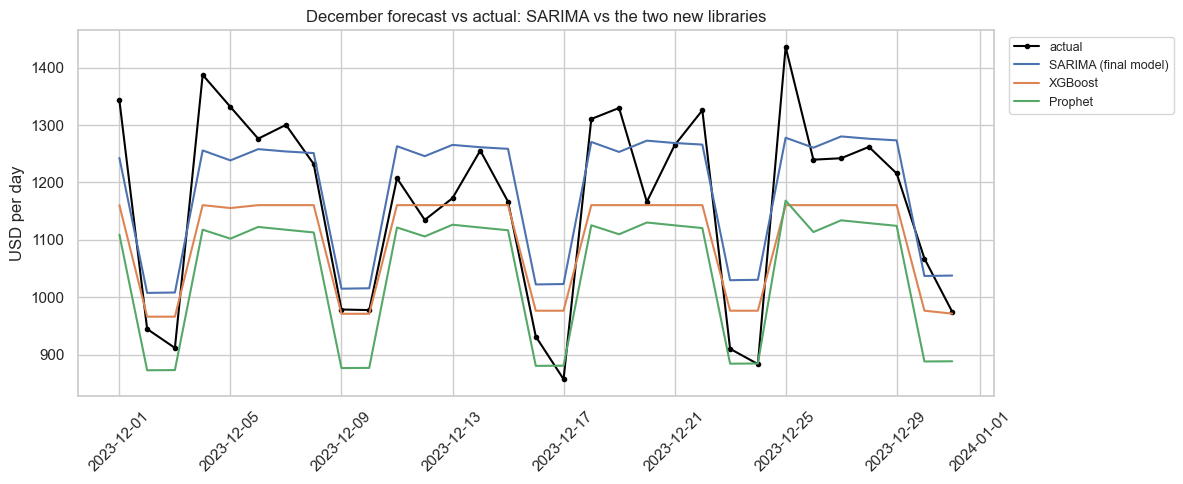

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(test, color='black', marker='o', markersize=3, label='actual')
plt.plot(preds['SARIMA'], label='SARIMA (final model)')
plt.plot(extra_preds['XGBoost'], label='XGBoost')
plt.plot(extra_preds['Prophet'], label='Prophet')
plt.title('December forecast vs actual: SARIMA vs the two new libraries')
plt.ylabel('USD per day')
plt.xticks(rotation=45)
plt.legend(fontsize=9, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('images/new_libraries.png', dpi=100)
plt.show()

Then the same backtest as section 10. XGBoost's grid search and Prophet's holdout tuning are both redone inside each month, using only the data before it.

In [33]:
extra_backtest = []
for month_start in pd.date_range('2023-04-01', '2023-12-01', freq='MS'):
    month_end = month_start + pd.offsets.MonthEnd(0)
    last_day = month_start - pd.Timedelta(days=1)
    history = daily[:last_day]
    actual = daily[month_start:month_end]

    month_xgb = clone(xgb_grid).fit(features[:last_day], daily[features[:last_day].index])
    cps = tune_prophet(history)

    extra_backtest.append({
        'month': month_start.strftime('%b'),
        'XGBoost': get_scores(actual, month_xgb.predict(features[month_start:month_end]))['MAPE %'],
        'Prophet': get_scores(actual, prophet_forecast(history, len(actual), cps))['MAPE %'],
        'Prophet cps': cps
    })

extra_backtest = pd.DataFrame(extra_backtest).set_index('month')
extra_backtest

,XGBoost,Prophet,Prophet cps
month,,,
Apr,4.61,4.90,0.10
May,4.99,4.82,0.10
Jun,12.36,15.22,0.10
Jul,6.47,4.17,0.01
Aug,10.69,14.81,0.01
Sep,7.60,6.79,0.50
Oct,5.81,5.69,0.05
Nov,20.75,22.73,0.50
Dec,7.40,9.79,0.01


In [34]:
normal_months = ['Apr', 'May', 'Jul', 'Sep', 'Oct', 'Dec']
shift_months = ['Jun', 'Aug', 'Nov']

all_models = mape_table[month_order].copy()
all_models.loc['XGBoost'] = extra_backtest['XGBoost']
all_models.loc['Prophet'] = extra_backtest['Prophet']
pd.DataFrame({
    'normal months': all_models[normal_months].mean(axis=1),
    'shift months': all_models[shift_months].mean(axis=1),
    'all 9 months': all_models.mean(axis=1)
}).round(2).sort_values('normal months')

,normal months,shift months,all 9 months
model,,,
SARIMA,5.65,17.41,9.57
Random Forest,5.97,15.59,9.18
STL + ARIMA,6.02,16.95,9.66
Prophet,6.03,17.59,9.88
XGBoost,6.15,14.60,8.96
Gradient Boosting,6.29,14.65,9.08
seasonal naive,7.08,16.90,10.36
Ridge,7.84,16.00,10.56
ARIMA,11.19,18.10,13.49


Here is what the two new libraries show:

- XGBoost ended up almost identical to the Gradient Boosting model from section 7. The grid search picked the same settings (learning rate 0.01, trees with one split, 300 trees, no row sampling), its CV MAPE was 8.81% vs 8.80%, and in December it was 7.4% vs 7.3%, with the same tendency to forecast about 5% too low. In the backtest it has the lowest 9 month average of all the models (8.96%), but that lead comes from the shift months, where every model is off by about 15% to 20% on average. In the normal months it's 6.15%, behind SARIMA (5.65%).
- Prophet did well in the normal months (6.03%, about the same as Random Forest and STL + ARIMA), but in the shift months (17.6%) it did worse than every model except plain ARIMA and the naive baseline. In December it was off by 9.8%, with the monthly total 10% too low. In the chart, its forecast sits below the actual spend for most of December. The holdout tuning picked a stiff trend (0.01), which most likely kept the forecast from moving up to November's higher level.
- Prophet's changepoints didn't help with the level shifts. A changepoint can only be found once the shift is already in the history, so like every other model, Prophet can't see a jump coming. The tuned setting also jumped between 0.01 and 0.5 from month to month, probably because the holdout month was sometimes a shift month and sometimes not.

So SARIMA stays the final model. It's still the most accurate in normal months, and it gives the 95% range used for the alert. Both libraries were easy to plug into the same tests (XGBoost works directly with `GridSearchCV`, and Prophet only needed a small tuning function), but with one year of data neither one found anything the course models had missed.

## 13. Residual check

The residuals of a good time series model should look like random noise around 0. I check SARIMA and STL + ARIMA on the training data, skipping the first two weeks, where the differencing has no history yet. The Ljung-Box test checks for leftover autocorrelation, where a p-value above 0.05 means none was found.

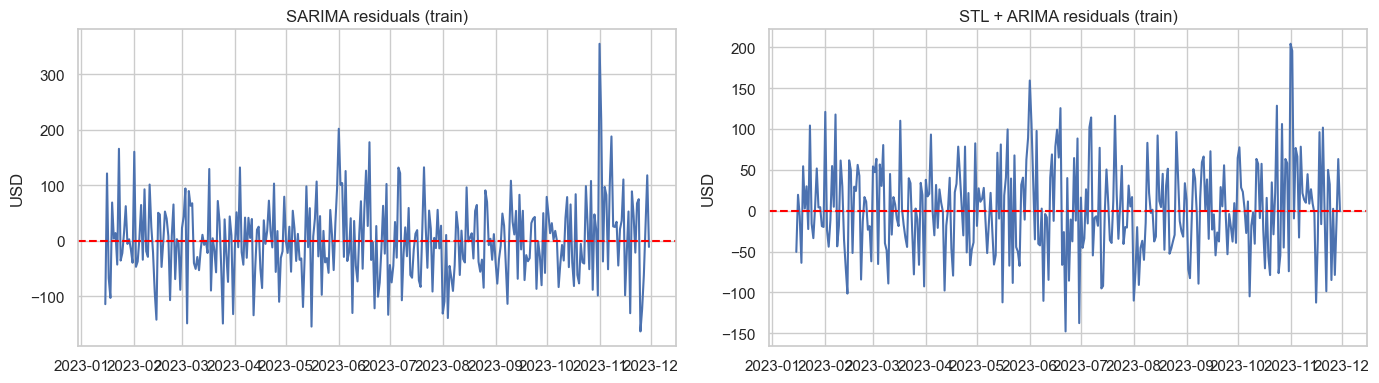

,SARIMA,STL + ARIMA
7,0.249,0.0
14,0.199,0.0


In [35]:
sarima_resid = sarima.resid[14:]
stl_resid = stl_arima.model_result.resid[14:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(sarima_resid)
axes[0].set_title('SARIMA residuals (train)')
axes[1].plot(stl_resid)
axes[1].set_title('STL + ARIMA residuals (train)')
for ax in axes:
    ax.axhline(0, color='red', linestyle='--')
    ax.set_ylabel('USD')
plt.tight_layout()
plt.show()

pd.DataFrame({
    'SARIMA': acorr_ljungbox(sarima_resid, lags=[7, 14])['lb_pvalue'],
    'STL + ARIMA': acorr_ljungbox(stl_resid, lags=[7, 14])['lb_pvalue']
}).round(3)

## 14. Modeling summary

The December results are in section 8. Here is a summary of the backtest from April to December (MAPE %), including XGBoost and Prophet from section 12:

| Model | Normal months (Apr, May, Jul, Sep, Oct, Dec) | Shift months (Jun, Aug, Nov) | All 9 months |
|---|---|---|---|
| SARIMA | 5.7 | 17.4 | 9.6 |
| Random Forest | 6.0 | 15.6 | 9.2 |
| STL + ARIMA | 6.0 | 17.0 | 9.7 |
| Prophet | 6.0 | 17.6 | 9.9 |
| XGBoost | 6.1 | 14.6 | 9.0 |
| Gradient Boosting | 6.3 | 14.6 | 9.1 |
| Seasonal naive | 7.1 | 16.9 | 10.4 |
| Ridge | 7.8 | 16.0 | 10.6 |
| ARIMA | 11.2 | 18.1 | 13.5 |
| Naive | 15.0 | 20.2 | 16.7 |

The weekly pattern matters the most. Plain ARIMA, which has no season, is barely better than the naive forecast, and adding the weekly season (SARIMA and STL + ARIMA) cuts the error roughly in half.

In the six normal months, SARIMA, Random Forest and STL + ARIMA all average about 6% or less, which is well under my 10% goal. SARIMA is the most consistent of them and never goes above 6.4% in a normal month. In June, August and November the spending level shifted (up 16%, down 10% and up 29%), and every model missed by 10% to 26%. A model that only looks at past cost has no way of knowing a shift like that is coming.

The tree models do a little better in the shift months (about 15% vs 17% for the time series models), which gives them the lowest 9 month averages, but they're less steady in normal months. In December, for example, they forecast about 5% too low. The top models are all within less than one percentage point of each other in normal months, and which one wins changes from month to month, so I don't want to read too much into the small differences.

Looking at the regression models more closely, the trees mostly learn day of week and month, Ridge fits a straight line that can't follow a sudden shift, and the 35 and 42 day lags add almost nothing. With only one year of data, I think they just can't learn much beyond what the time series models already capture. I also noticed that the settings with the best cross-validation score don't always win on the test month. Gradient Boosting had the best CV score (8.8%) but was only average in December, which is why I compare the models on the 9 month backtest instead of a single split.

I also tried to improve the regression models in three ways, and none of them changed the picture much. More tuning (section 9) helped on the CV folds by about 1 to 1.5 points, but the gains were smaller than the noise between folds. More features (section 11) didn't help, and letting feature selection pick a small set made December a lot worse. XGBoost ended up almost the same as Gradient Boosting, and Prophet was fine in normal months but near the bottom when spend jumped (section 12).

The SARIMA residuals look like random noise, and the Ljung-Box test doesn't find any leftover autocorrelation (p-values of 0.25 and 0.20). The STL + ARIMA residuals still have some (p < 0.05).

I'm picking SARIMA as the final model. It's the most accurate and consistent in normal months, its residuals are clean, and it gives a 95% interval for each day that I can use as an alert, so one model covers both the forecast and the alert. In December it was off by 6.4% per day and 1.9% on the monthly total.

The main limitation is the level shifts. The forecast works well as a baseline for normal spend, so the practical use is to compare actual spend against it and flag days that go well above it. More years of data would also help the models learn yearly patterns.

## 15. Using the forecast as a spend alert

None of the models could predict the level shifts in June and November. For the business though, there's another useful question: would the forecast at least warn us quickly when spend moves?

SARIMA gives a 95% interval with every forecast, and I use it as the normal range for each day. For a few months I train SARIMA on the data before the month, forecast the month, and count how many days actual spend went above the range. October and December are normal months, and June and November are shift months.

In [36]:
alert_results = []
alert_bands = {}

for month in ['2023-06', '2023-10', '2023-11', '2023-12']:
    month_start = pd.Timestamp(month + '-01')
    history = daily[:month_start - pd.Timedelta(days=1)]
    actual = daily[month]

    # same as the backtest: pick the orders using only the data before this month
    best = search_sarima(history).loc[0]
    model = SARIMAX(history, order=best['order'], seasonal_order=best['seasonal_order'],
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    forecast = model.get_forecast(len(actual))
    band = forecast.conf_int()
    band.columns = ['lower', 'upper']
    band['forecast'] = forecast.predicted_mean
    band['actual'] = actual
    alert_bands[month] = band

    above = band[band['actual'] > band['upper']]
    alert_results.append({
        'month': month_start.strftime('%b'),
        'days above range': len(above),
        'days in month': len(actual),
        'first alert': above.index.min().strftime('%b %d') if len(above) > 0 else '-'
    })

pd.DataFrame(alert_results)

,month,days above range,days in month,first alert
0,Jun,16,30,Jun 01
1,Oct,0,31,-
2,Nov,24,30,Nov 01
3,Dec,0,31,-


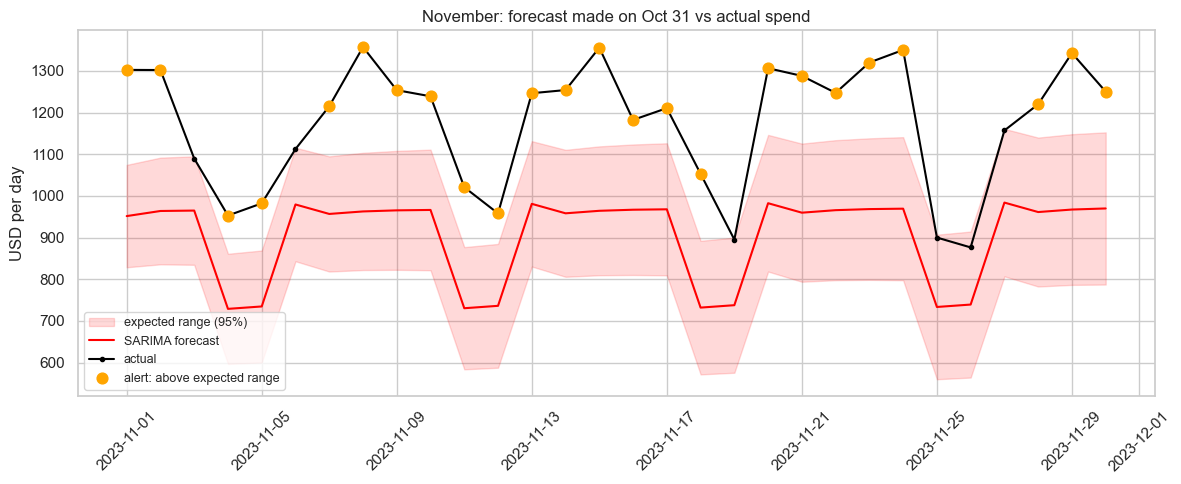

In [37]:
band = alert_bands['2023-11']
flagged = band[band['actual'] > band['upper']]

plt.figure(figsize=(12, 5))
plt.fill_between(band.index, band['lower'], band['upper'], color='red', alpha=0.15, label='expected range (95%)')
plt.plot(band['forecast'], color='red', label='SARIMA forecast')
plt.plot(band['actual'], color='black', marker='o', markersize=3, label='actual')
plt.scatter(flagged.index, flagged['actual'], color='orange', s=60, zorder=3, label='alert: above expected range')
plt.title('November: forecast made on Oct 31 vs actual spend')
plt.ylabel('USD per day')
plt.xticks(rotation=45)
plt.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.savefig('images/spend_alert.png', dpi=100)
plt.show()

In the two normal months (October and December) no days went above the range, so there were no false alarms. In both shift months the alert went off on the first day: 24 of 30 days in November and 16 of 30 days in June were above the range. In November the first two days were both flagged, so a team watching this would have known by November 2 that spend had moved to a new level, instead of finding out when the bill came in December.

So even though the forecast can't predict a level shift, it catches one within a day or two, which I think is the most useful result for the business.

## 16. Findings and recommendations

I tried to write this section so it makes sense without the technical details above.

Spend has a strong weekly rhythm. Weekends cost about 24% less than weekdays ($796 vs $1,042 a day), and the t-test confirms this isn't random (p < 0.001). Spend also doesn't grow smoothly. It went up 16% in June, down 10% in August and up 29% in November, and the October to November jump is statistically significant (p < 0.001). My Module 16 proposal expected higher spend at the end of each month, but the data doesn't show that (p = 0.59).

In normal months the forecast is accurate. SARIMA was off by about 5.7% per day on average, which is under my 10% goal, and its December total was only 1.9% off. None of the models could predict the jumps, and in June, August and November they were all off by 10% to 26%. But the forecast range did catch the jumps quickly. It flagged November on the first day and didn't raise any false alarms in the normal months I checked.

I also tried more tuning, eight extra features and two libraries from outside the course (XGBoost and Prophet), and none of them did better than SARIMA in the normal months, so the simpler model stays.

Prod is 77% of the spend. Dev only drops about 20% on weekends, and together dev and staging cost about $19,000 a year just on weekends.

Based on these findings, my recommendations are:

1. Use the forecast to set next month's budget, and refit it every month with the latest data. It only takes a few seconds to run.
2. Set up a daily alert for when spend goes above the forecast range. If that happens two days in a row, check with the teams what changed (a new launch, a migration, a new workload) and update the budget then, instead of waiting for the monthly bill.
3. Focus cost reviews on prod. Saving 5% in prod is worth about $13,700 a year, which is more than what dev costs on all the weekends combined ($5,300).
4. Scale down dev and staging on weekends. This could save up to about $19,000 a year, or about 5% of the total. That's the maximum though, since some non-prod work probably does need to run on weekends.
5. There's no need to plan for higher spend at the end of the month, since the data doesn't show it.

Since the dataset is synthetic and only covers one year, these numbers should be checked on real billing data before acting on them.

## 17. Next steps

- Try the same approach on real billing data with more than one year of history, so the models can learn yearly patterns like the November increase.
- Add known events like launches or migrations as features, so planned jumps can be forecast instead of only caught after they happen.
- Forecast prod, staging and dev separately. Each one has a different weekend pattern, and separate alerts would show where a change came from.
- Try different alert ranges (for example 80% instead of 95%) and see how many real changes and false alarms each one gives.
- Usage from 35 days earlier was the only new feature in section 11 that helped a little. With more history it might be worth adding back, or using as an extra input to SARIMA or Prophet.